In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import random
import sys
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../../../atlas_extension/mapqc/")
import mapqc
import plotting

In [2]:
from scipy.stats import kstest

In [3]:
%load_ext lab_black

In [4]:
%load_ext autoreload
%autoreload 2

In [5]:
atlas_path = "../../data/HLCA_full_v1.1_emb.h5ad"

In [6]:
adata_full = sc.read_h5ad(atlas_path)

subset to query batch of choice:

In [7]:
query_batch = "Banovich_Kropski_2020"

In [8]:
adata = adata_full[
    (adata_full.obs.core_or_extension == "core")
    | (adata_full.obs.dataset == query_batch)
].copy()

add precalculated umap coordinates:

In [9]:
umap_coords = pd.read_csv(f"./umaps/{query_batch}_umap.csv", index_col=0)

In [10]:
adata.obsm["X_umap"] = umap_coords.loc[adata.obs.index, :].values

### Prepare adata:

In [11]:
ref_q_key = "core_or_extension"
batch_key = "dataset"
ref_cat = "core"
query_cat = "extension"
condition_key = "lung_condition"

In [12]:
if query_batch in (adata.obs.loc[adata.obs[ref_q_key] == ref_cat, batch_key].values):
    print(f"Setting batch {query_batch} to 'query' as query simulation.")
    adata.obs[ref_q_key] = adata.obs[ref_q_key].tolist()
    adata.obs.loc[adata.obs[batch_key] == query_batch, ref_q_key] = query_cat

Setting batch Banovich_Kropski_2020 to 'query' as query simulation.


In [13]:
adata.obs.loc[adata.obs.dataset == query_batch, condition_key].unique()

['Healthy', 'Sarcoidosis', 'IPF', 'ILD', 'HP', 'NSIP']
Categories (7, object): ['HP', 'Healthy', 'Healthy (tumor adjacent)', 'ILD', 'IPF', 'NSIP', 'Sarcoidosis']

In [14]:
condition_of_interest = "Healthy"
print(f"Subsetting query to condition {condition_of_interest}")
adata_healthy = adata[
    (adata.obs[ref_q_key] == ref_cat)
    | (adata.obs[condition_key] == condition_of_interest)
].copy()

Subsetting query to condition Healthy


In [15]:
condition_of_interest = "IPF"
print(f"Subsetting query to condition {condition_of_interest}")
adata_disease = adata[
    (adata.obs[ref_q_key] == ref_cat)
    | (adata.obs[condition_key] == condition_of_interest)
].copy()

Subsetting query to condition IPF


### Run mapQC on healthy:

In [16]:
n_nhoods = 100
k = 1000

In [17]:
query_cell_idc_healthy = np.where(adata_healthy.obs[ref_q_key] == query_cat)[0].tolist()
random.seed(0)
center_cell_idc_healthy = random.sample(query_cell_idc_healthy, k=n_nhoods)
center_cells_healthy = np.array(
    adata_healthy.obs.iloc[center_cell_idc_healthy, :].index
)

In [18]:
results_healthy = mapqc.mapQC_results(
    adata=adata_healthy,
    center_cells=center_cells_healthy,
    k=k,
    emb_key="X",
    ref_q_key="core_or_extension",
    ref_cat="core",
    query_cat="extension",
    batch_key="dataset",
    exclude_same_batch_for_ref_samples=True,
)

../../../atlas_extension/mapqc/mapqc.py:137: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  self._nhood_filtered = pd.Series(index=self.center_cells)


In [19]:
results_healthy.calculate_sample_dists_to_ref_samples()

100it [00:27,  3.65it/s]
../../../atlas_extension/mapqc/mapqc.py:242: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)
../../../atlas_extension/mapqc/mapqc.py:246: RuntimeWarning: Mean of empty slice
  nhood_ref_mean_dists = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1872: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [20]:
results_healthy.calculate_nhood_statistics()

88% of neighborhoods passed filtering.
8% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.


../../../atlas_extension/mapqc/mapqc.py:311: RuntimeWarning: Mean of empty slice
  mean_zscored_q_dist_to_ref = np.nanmean(


In [21]:
results_healthy.nhood_stats

,ks_stat,pval,nhood_number,nhood_weight,pval_corr,sign,mean_zscored_q_dist_to_ref
GCTGCGAAGGCAGTCA_F01641,0.30303,0.252601,0,0.885833,0.623644,False,0.416912
CTACACCTCGTCACGG_F02528,0.181034,0.584154,1,0.947500,0.888495,False,0.266208
CTACACCTCCATGAAC_F02524,0.2875,0.297228,2,0.857333,0.694941,False,0.743527
GCAAACTTCGTTACGA_F02509,0.0625,0.891293,3,0.948833,1.0,False,-0.369700
GGACGTCAGCCAGTAG_F02526,0.378205,0.114503,4,0.907500,0.382271,False,0.728013
...,...,...,...,...,...,...,...
CCATGTCCACGCCAGT_F01851,0.045455,0.944608,95,0.765150,1.0,False,-0.399809
GCTCTGTCATGGTCTA_F02611,0.288889,0.363366,96,0.892333,0.743184,False,-0.265245
CCGTACTAGGACATTA_F02522,0.142857,0.676949,97,0.792250,0.960059,False,-0.044886
TATGCCCTCCGCGTTT_F02617,0.099265,0.783188,98,0.995333,1.0,False,-0.473658


In [22]:
# temp = results_healthy.adata[results_healthy.adata.obs.core_or_extension != "core", :]
# sc.pp.neighbors(temp, n_neighbors=30)
# sc.tl.umap(temp)
# sc.pl.umap(
#     temp,
#     color="core_or_extension",
#     palette={
#         results_healthy.ref_cat: "tab:orange",
#         results_healthy.query_cat: "tab:blue",
#     },
#     title=f"{query_batch} (disease)",
#     frameon=False,
# )

In [23]:
# sc.pl.umap(
#     results_healthy.adata[results_healthy.adata.obs.core_or_extension == "core", :],
#     color="core_or_extension",
#     palette={
#         results_healthy.ref_cat: "tab:orange",
#         results_healthy.query_cat: "tab:blue",
#     },
#     title=f"{query_batch} (disease)",
#     frameon=False,
# )

check how many reference samples per neighborhood atm:

In [ ]:
results_healthy.

### Plot:

In [24]:
sc.set_figure_params(figsize=(5, 5))

#### healthy:

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


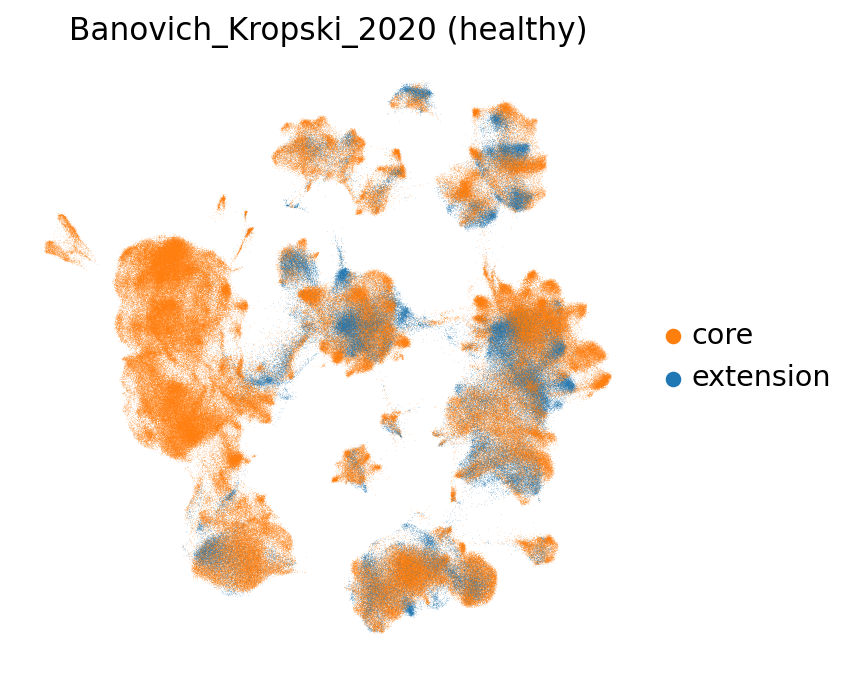

In [25]:
sc.pl.umap(
    results_healthy.adata,
    color="core_or_extension",
    palette={
        results_healthy.ref_cat: "tab:orange",
        results_healthy.query_cat: "tab:blue",
    },
    title=f"{query_batch} (healthy)",
    frameon=False,
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


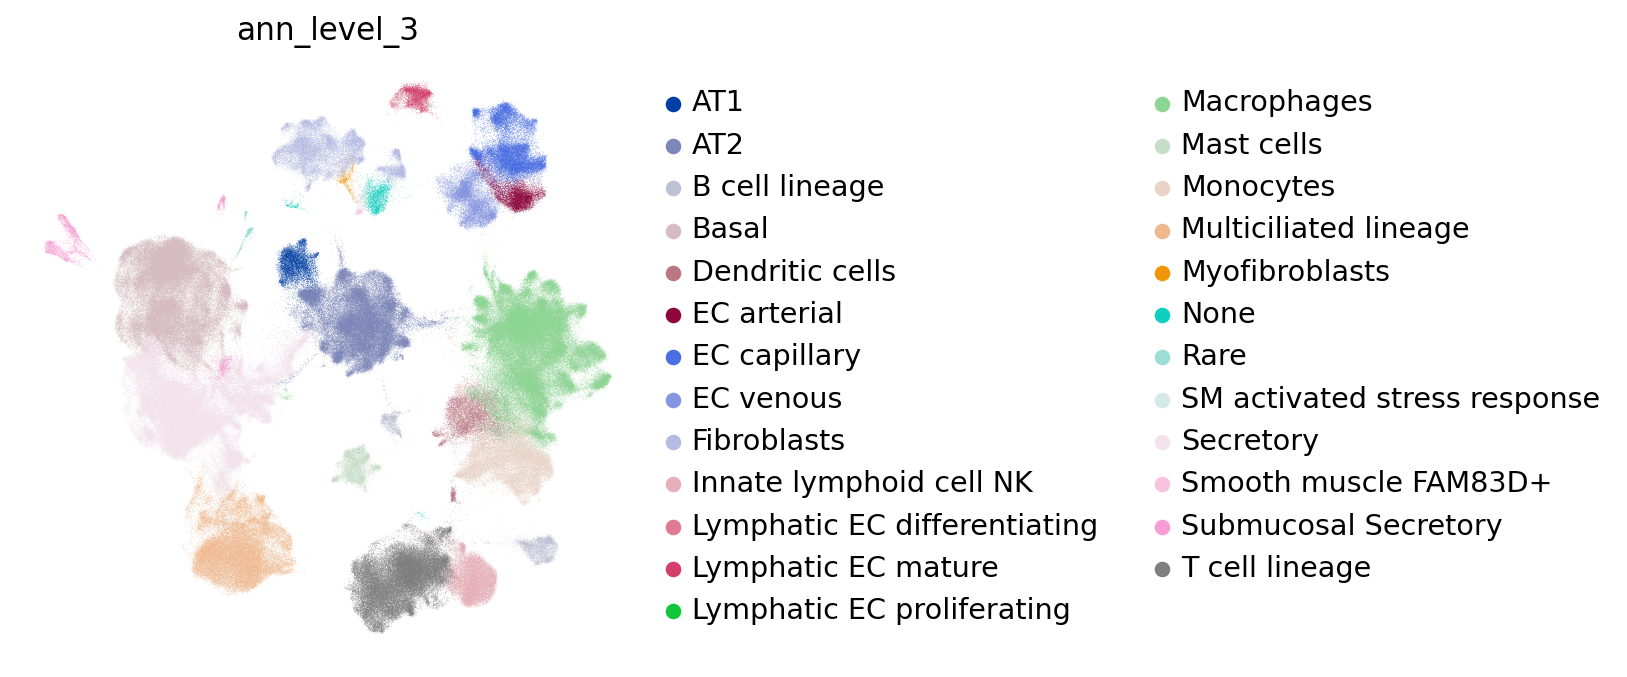

In [26]:
sc.pl.umap(
    results_healthy.adata,
    color="ann_level_3",
    # title=f"{query_batch} (disease)",
    frameon=False,
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


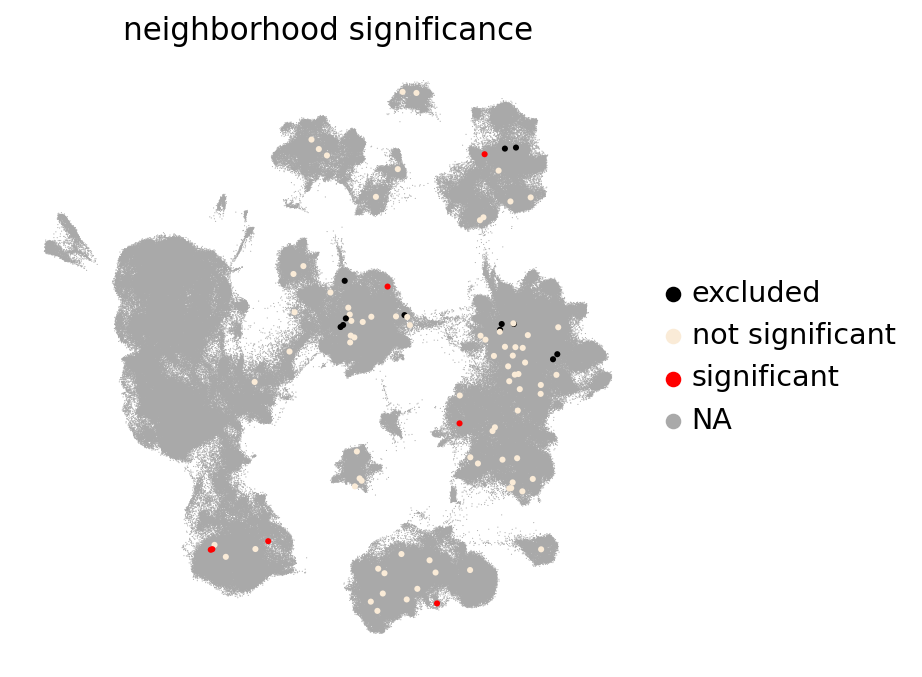

In [27]:
plotting.plot_umap_significance(results_healthy)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


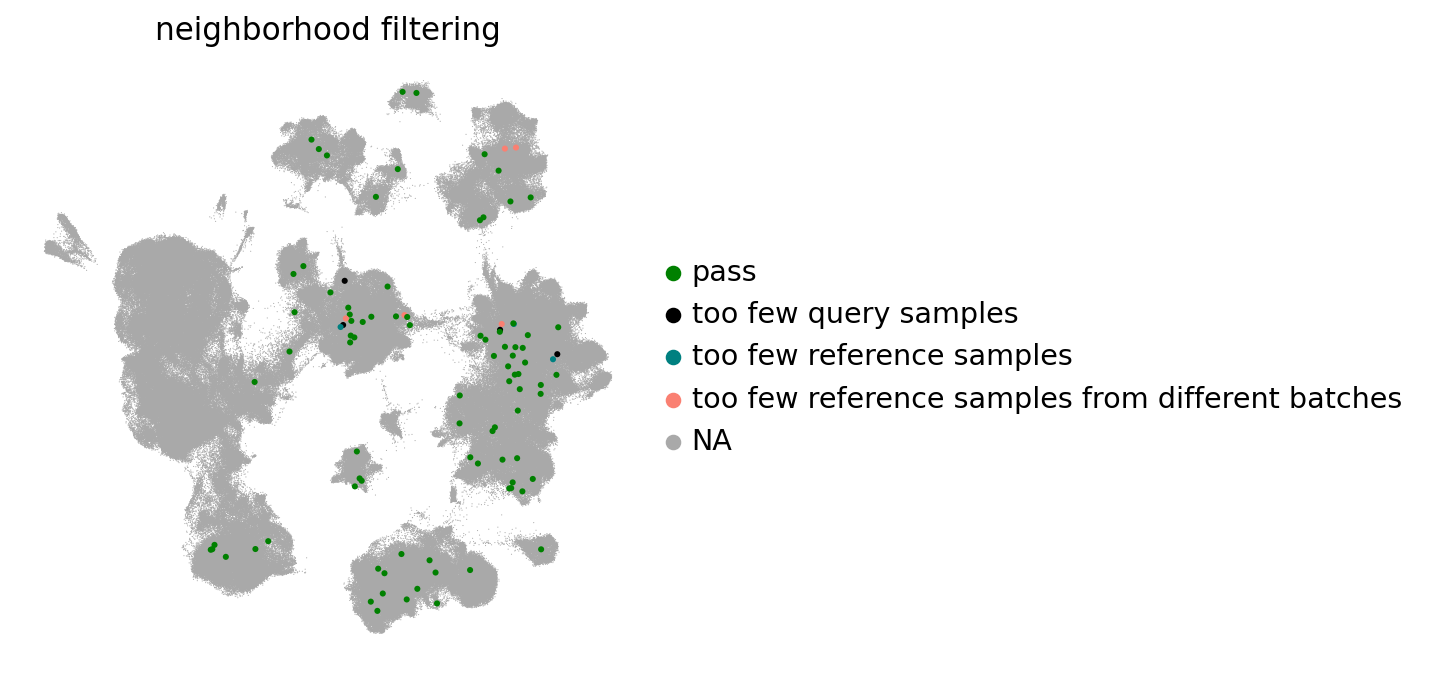

In [28]:
plotting.plot_umap_filtering_info(results_healthy)

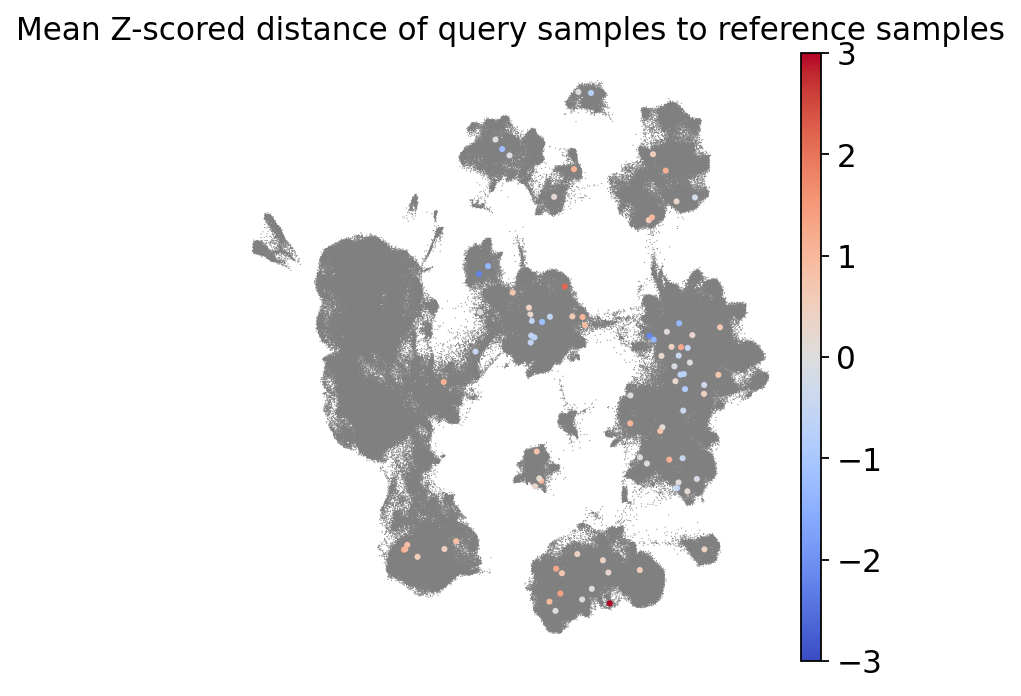

In [29]:
plotting.plot_umap_zscored_q_dist_to_ref(results_healthy)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


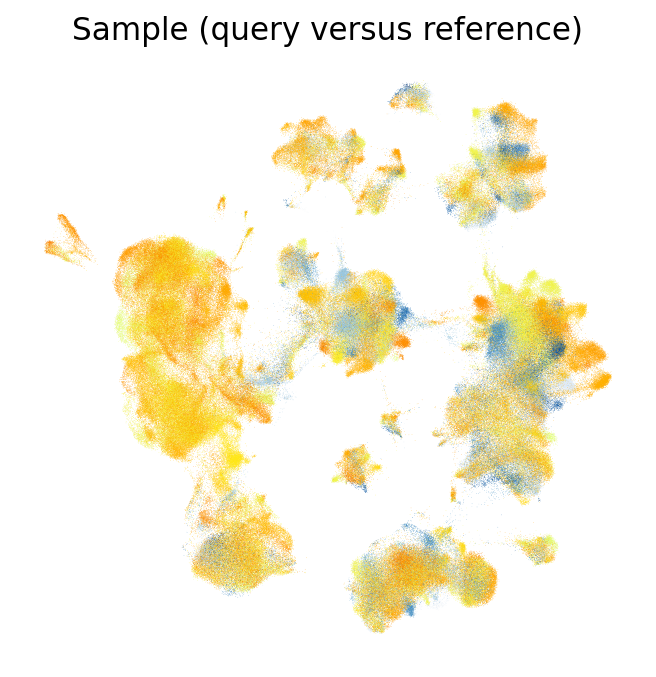

In [30]:
plotting.plot_umap_q_ref_sample_shaded(results_healthy)

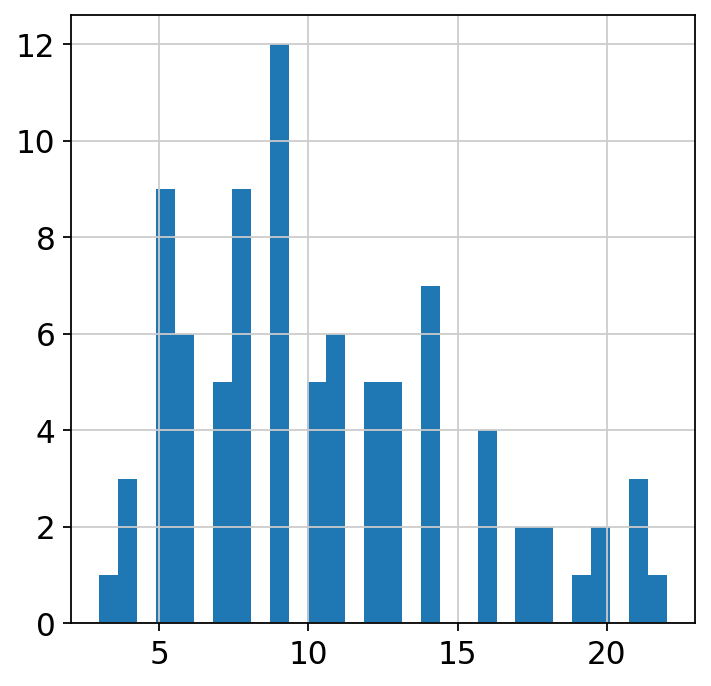

In [65]:
plt.hist(
    results_healthy._boxplot_df_mean_sample_dists_to_ref.groupby(
        [
            "sample_r_or_q",
            "nhood",
        ]
    )
    .agg({"sample": "nunique"})
    .loc["extension", :],
    bins=30,
)
plt.show()

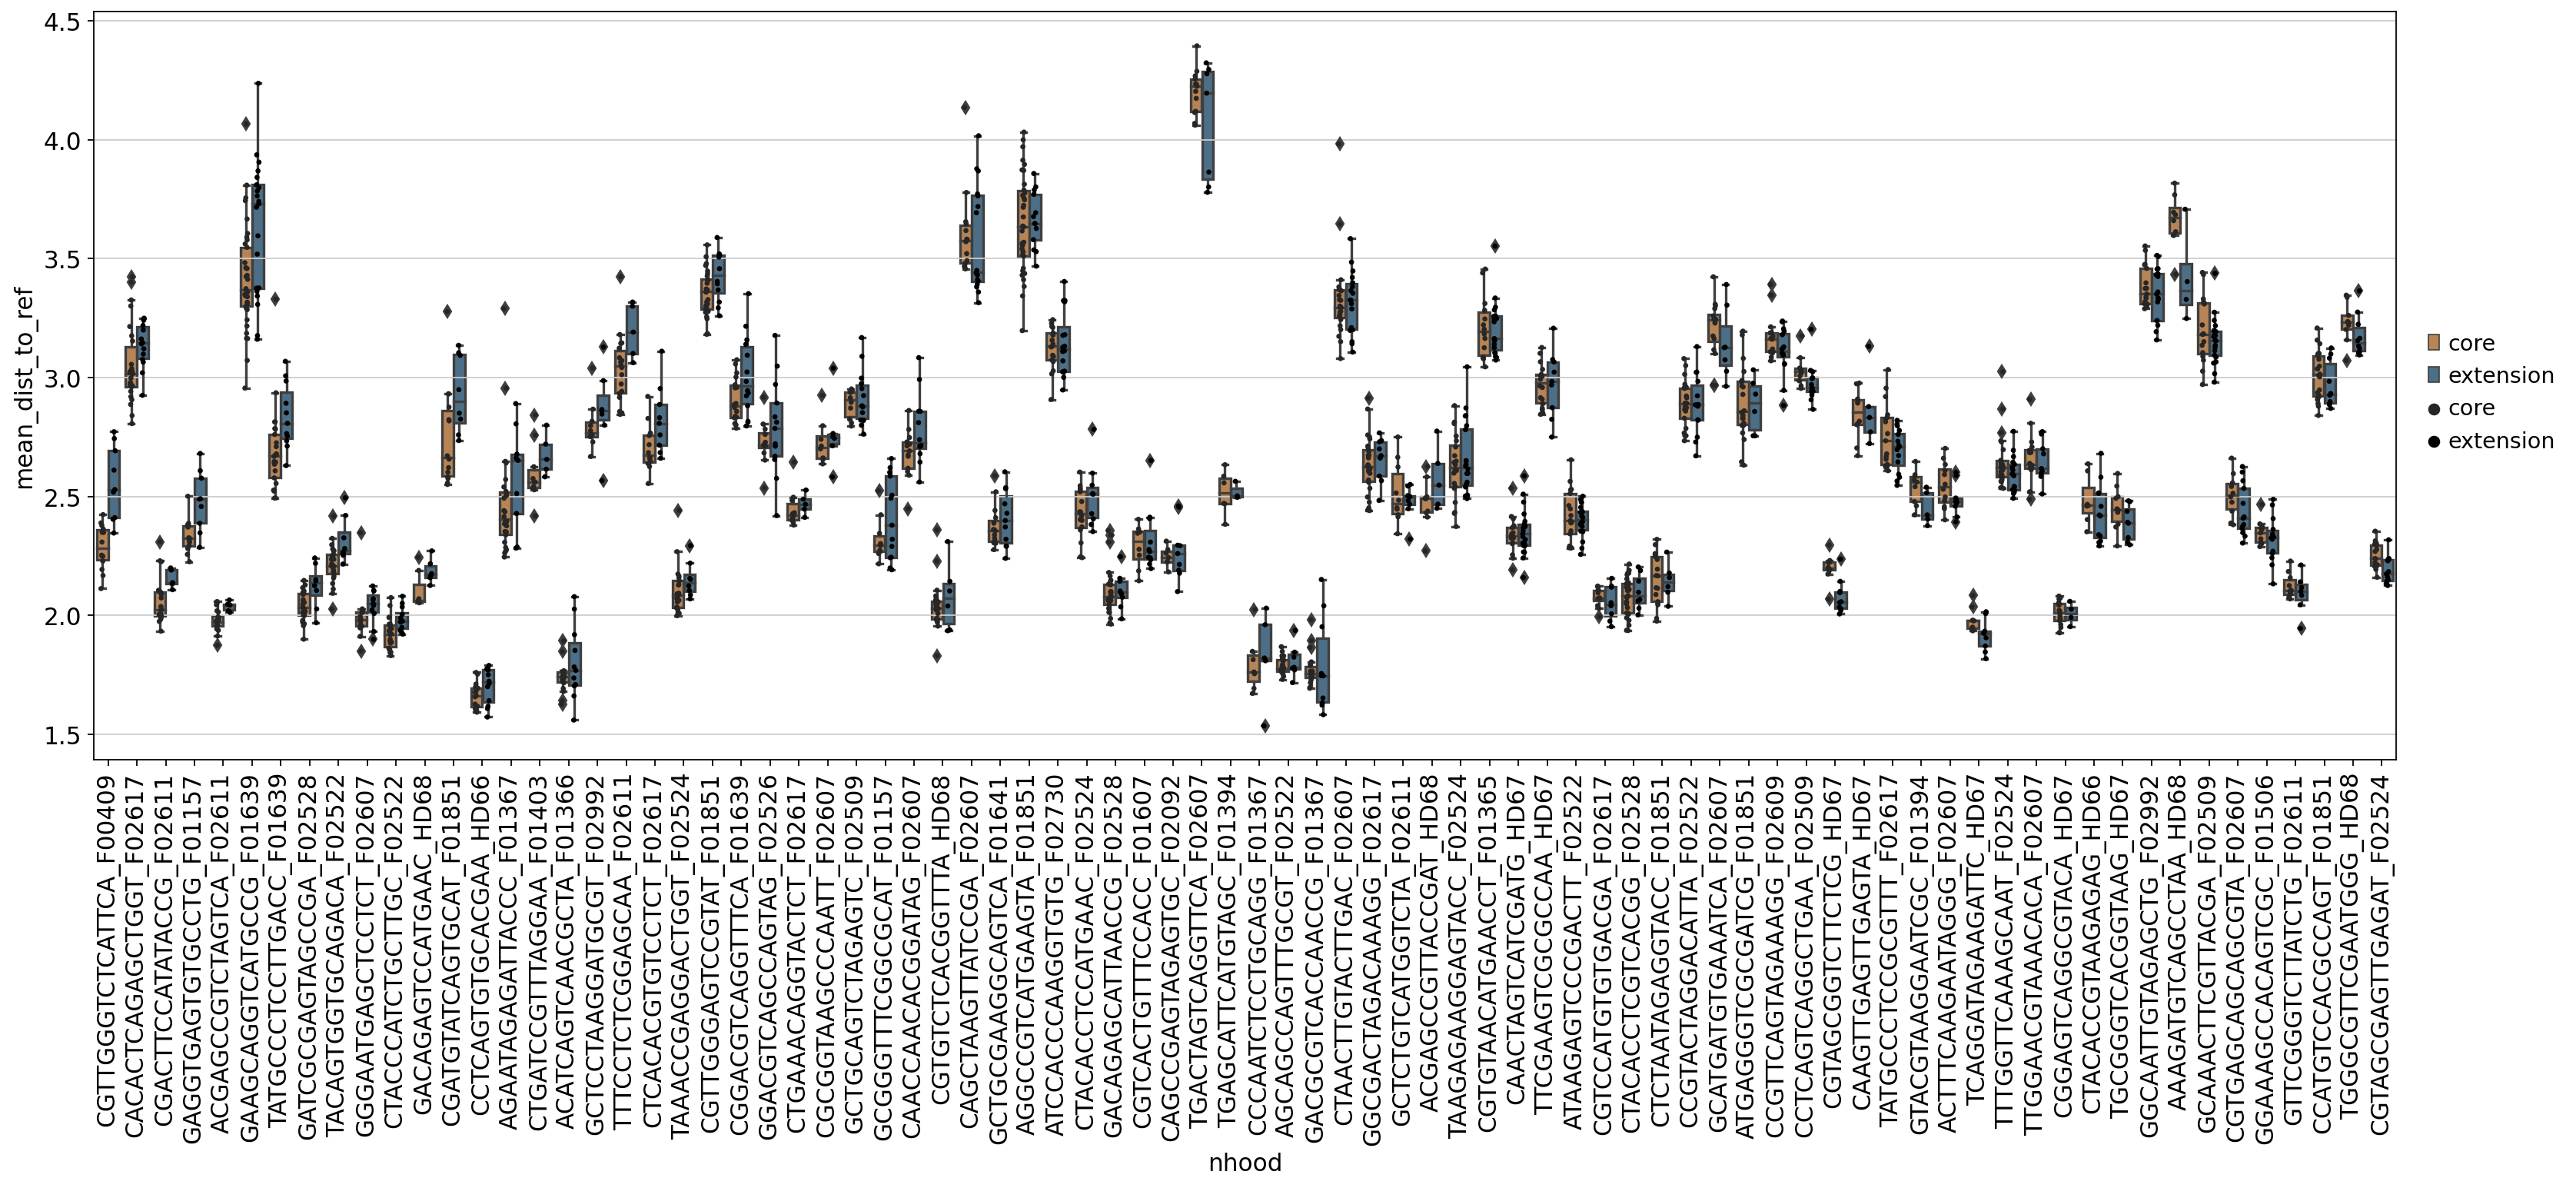

In [31]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(results_healthy)

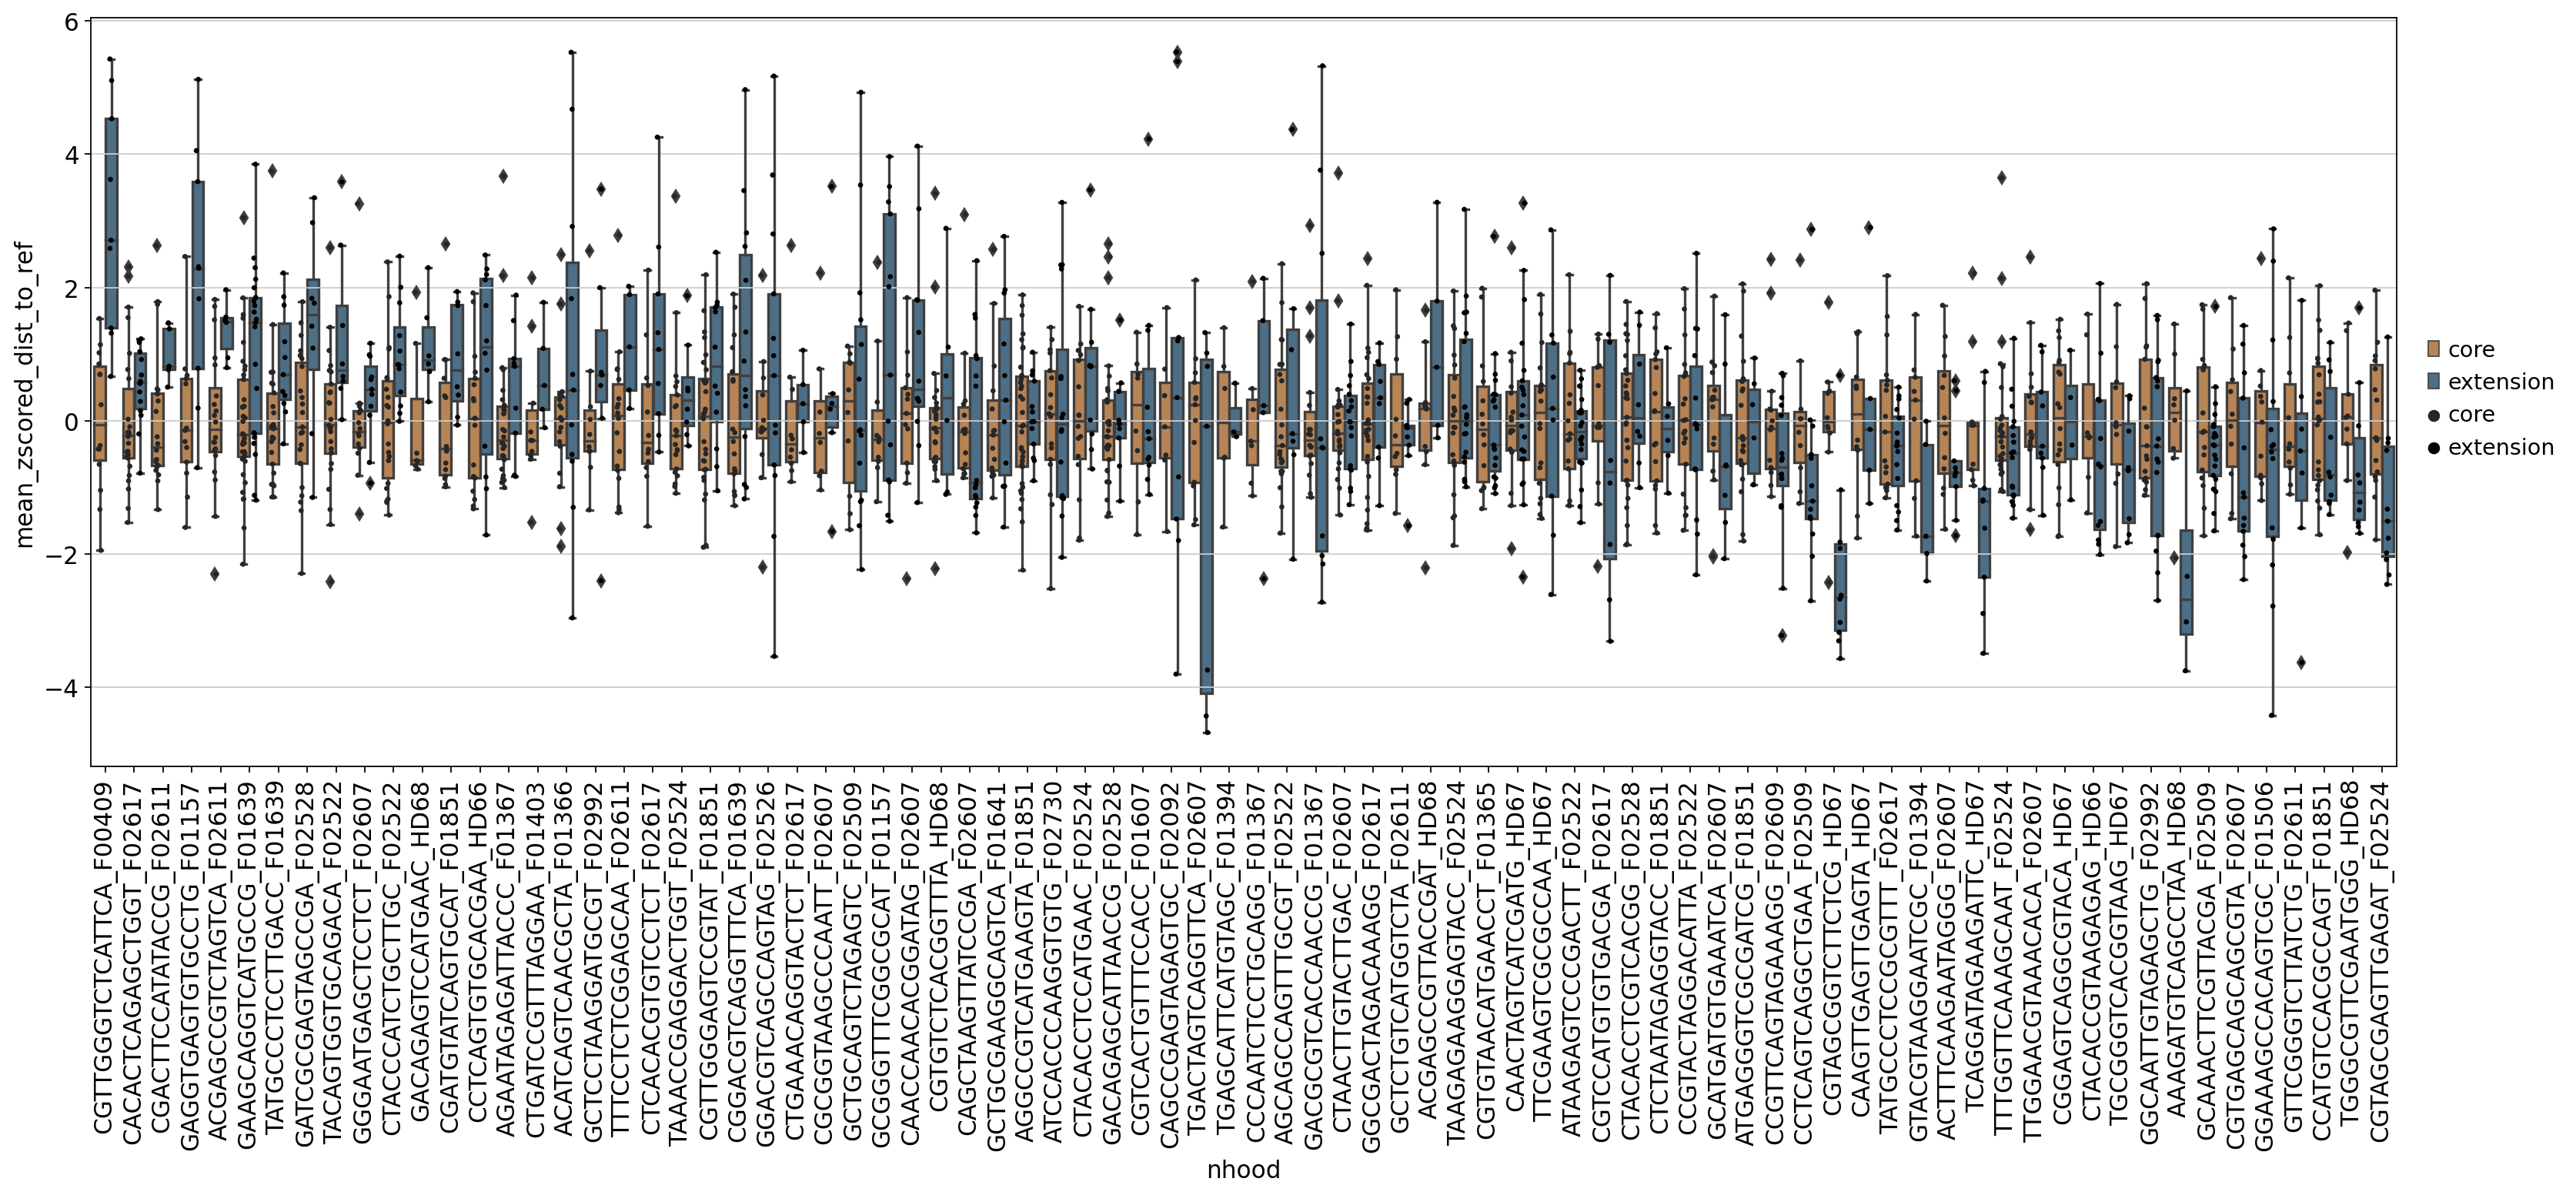

In [32]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(
    results_healthy, use_zscored_dists=True
)

#### Aggregate according to pre-determined partitioning (e.g. cell type)

/tmp/ipykernel_3763502/3168527951.py:14: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(


Text(0.5, 0, 'Cell type')

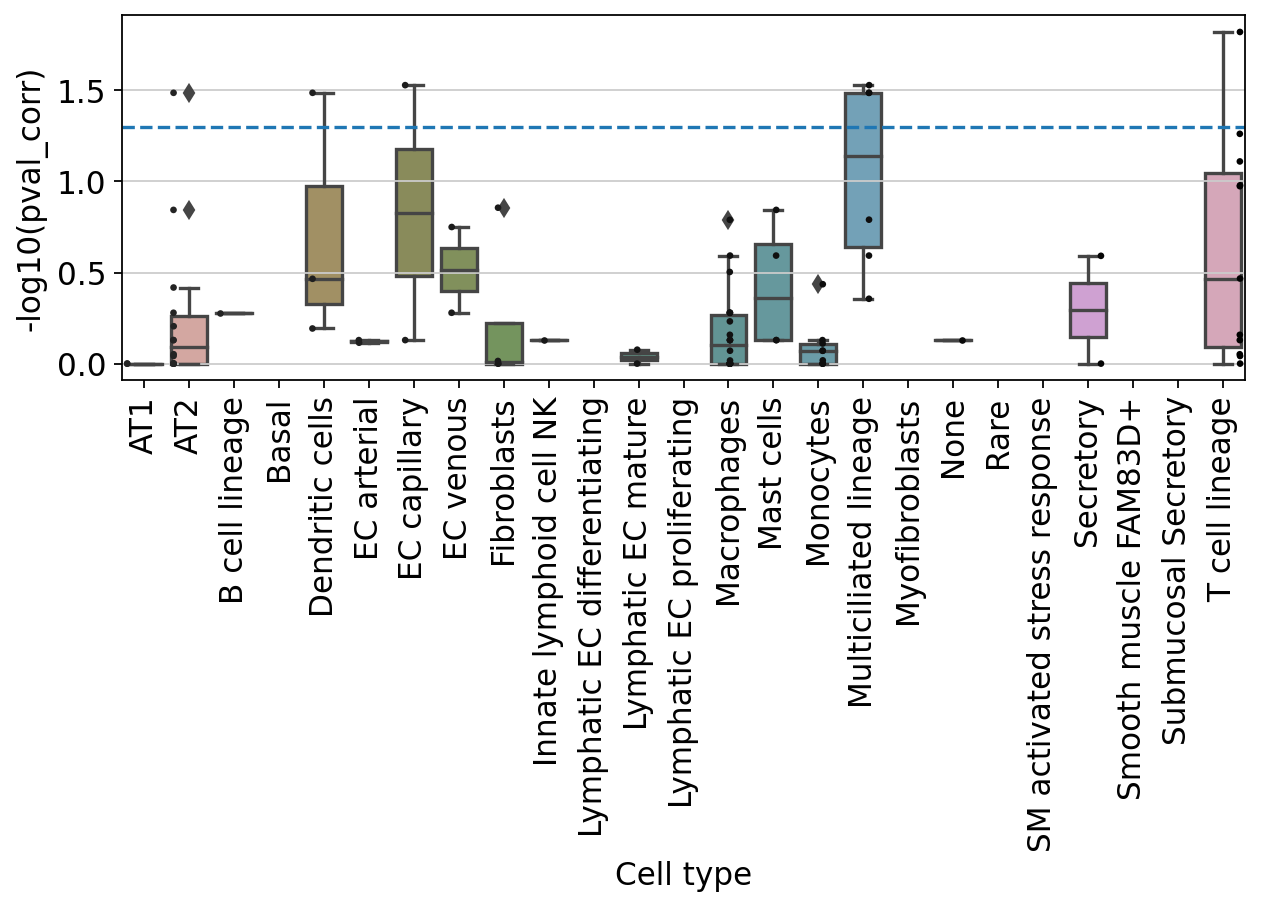

In [33]:
partitioning_key = "ann_level_3"
stats_df_healthy = results_healthy.nhood_stats.copy()
stats_df_healthy[partitioning_key] = results_healthy.adata.obs.loc[
    stats_df_healthy.index, partitioning_key
]
stats_df_healthy["-log10(pval_corr)"] = -np.log10(
    stats_df_healthy.pval_corr.values.astype(float)
)
fig = plt.figure(figsize=(9, 3))
ax = fig.add_subplot()
sns.boxplot(
    stats_df_healthy, x=partitioning_key, y="-log10(pval_corr)", ax=ax, saturation=0.4
)
sns.stripplot(
    stats_df_healthy,
    x=partitioning_key,
    y="-log10(pval_corr)",
    dodge=True,
    ax=ax,
    size=3,
    palette="dark:black",
)
plt.axhline(-np.log10(0.05), linestyle="--")
ax.tick_params(axis="x", rotation=90)
ax.set_xlabel("Cell type")

#### zoom in on neighborhood in cell type of interest:

In [34]:
results_healthy.nhood_stats["cell_type"] = results_healthy.adata.obs.loc[
    results_healthy.nhood_stats.index, "ann_level_3"
]

In [35]:
ctoi_1 = "AT2"
nhood_of_int_healthy = results_healthy.nhood_stats.index[
    np.where(results_healthy.nhood_stats.cell_type == ctoi_1)[0][0]
]

../../../atlas_extension/mapqc/plotting.py:330: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mapqc_results.adata.obs[f"mapqc_nhood_cells_{neighborhood}"].iloc[
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


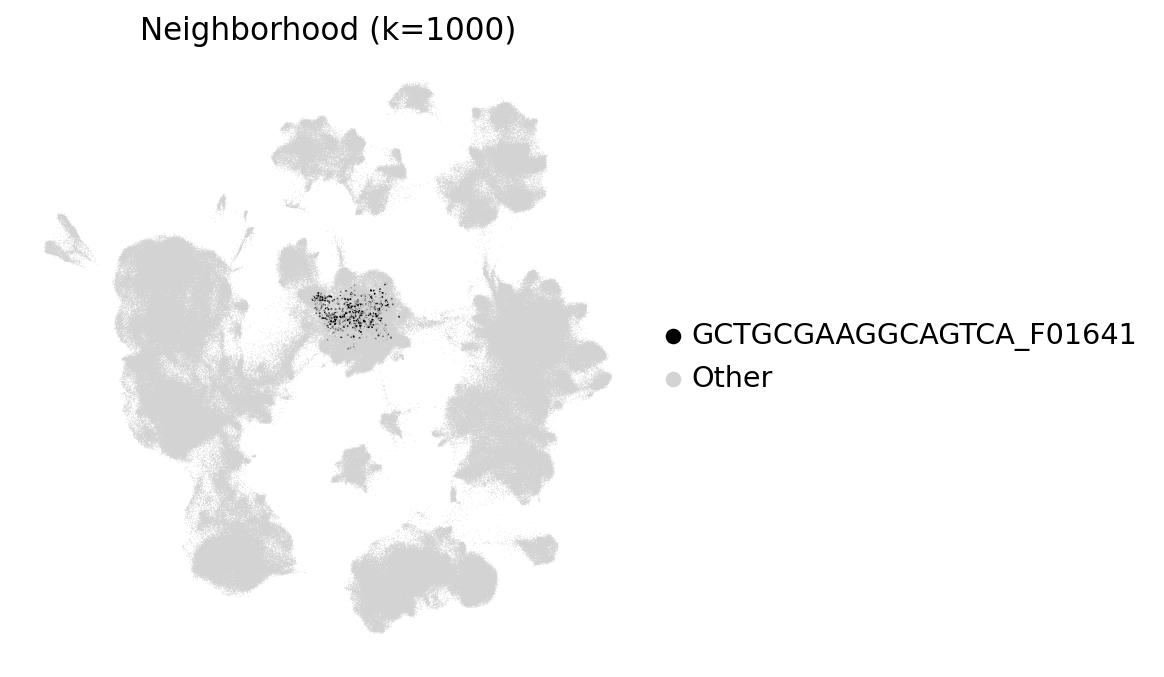

In [36]:
plotting.plot_umap_neighborhood(
    results_healthy, neighborhood=nhood_of_int_healthy, scale=0.5
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


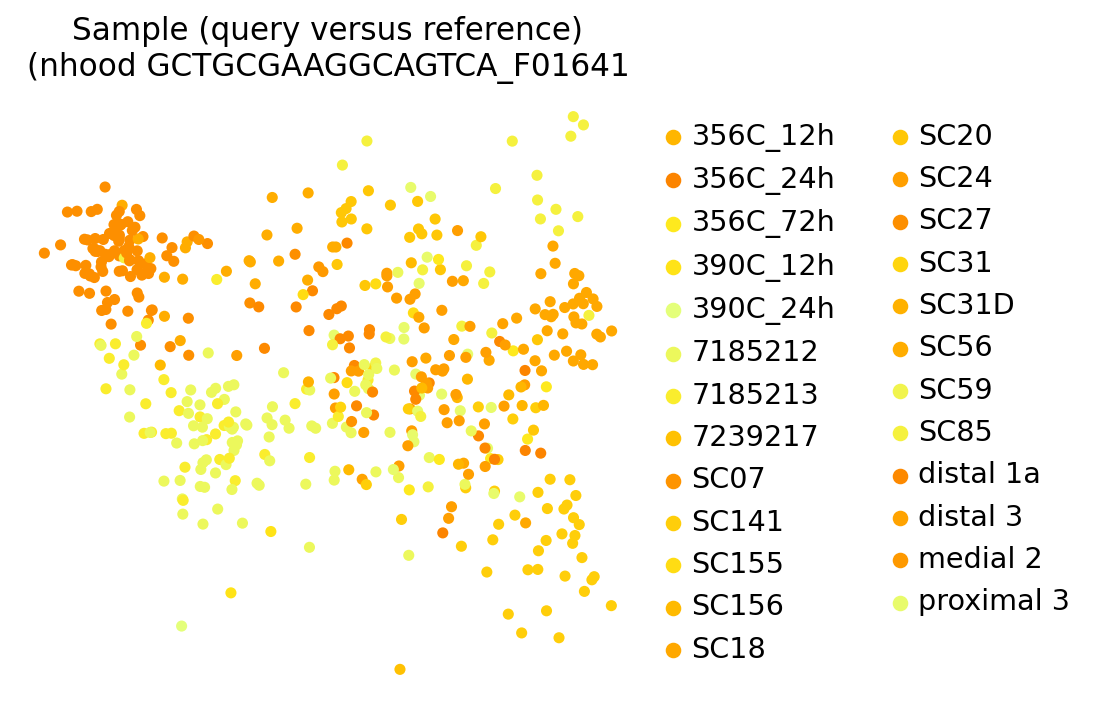

In [37]:
plotting.plot_umap_q_ref_sample_shaded(
    results_healthy,
    neighborhood=nhood_of_int_healthy,
    include_legend=True,
    reference_only=True,
    seed=0,
    dotsize=100,
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


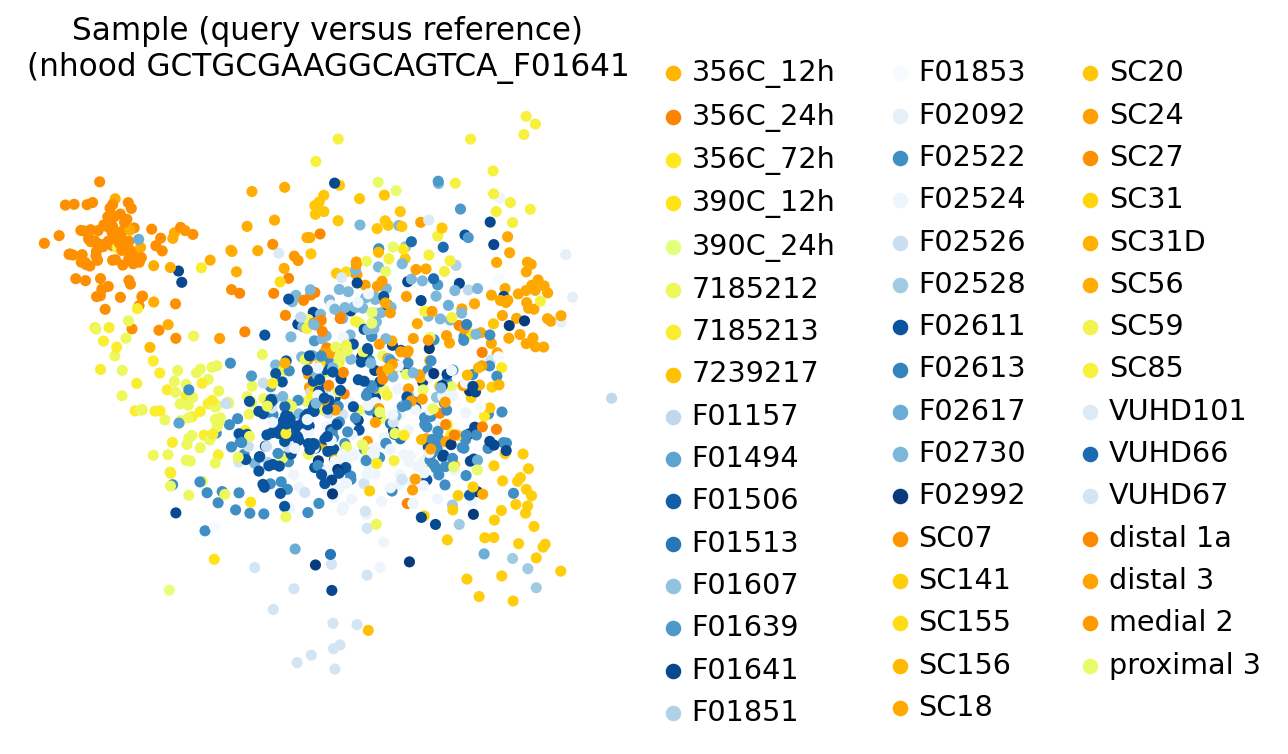

In [38]:
plotting.plot_umap_q_ref_sample_shaded(
    results_healthy,
    neighborhood=nhood_of_int_healthy,
    include_legend=True,
    seed=0,
    dotsize=100,
)

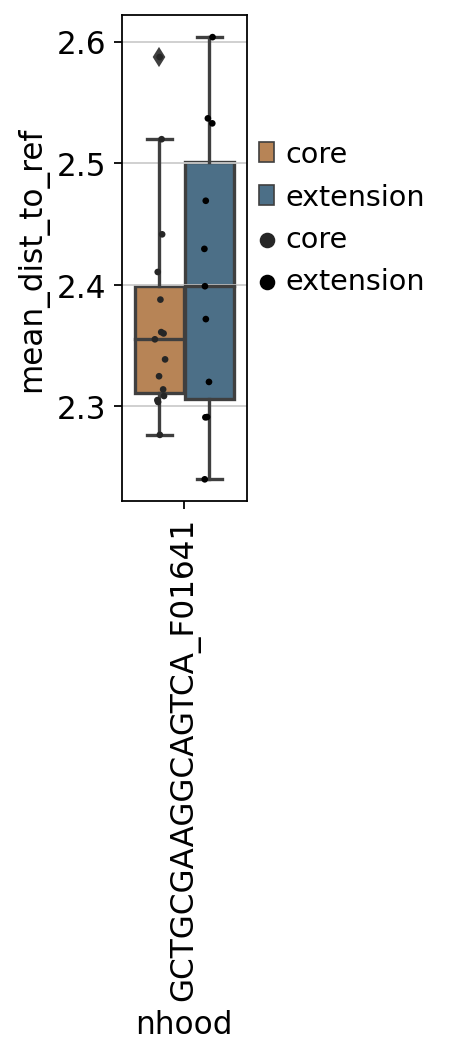

In [39]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(
    results_healthy, neighborhood=nhood_of_int_healthy
)

In [40]:
results_healthy.nhood_stats.loc[nhood_of_int_healthy, :]

ks_stat                        0.30303
pval                          0.252601
nhood_number                         0
nhood_weight                  0.885833
pval_corr                     0.623644
sign                             False
mean_zscored_q_dist_to_ref    0.416912
cell_type                          AT2
Name: GCTGCGAAGGCAGTCA_F01641, dtype: object

#### Zoom in on significantly differentially mixing nhood:

In [41]:
nhood_of_int_healthy_sign = results_healthy.nhood_stats.sort_values(
    by="pval_corr"
).index[0]

../../../atlas_extension/mapqc/plotting.py:330: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mapqc_results.adata.obs[f"mapqc_nhood_cells_{neighborhood}"].iloc[
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


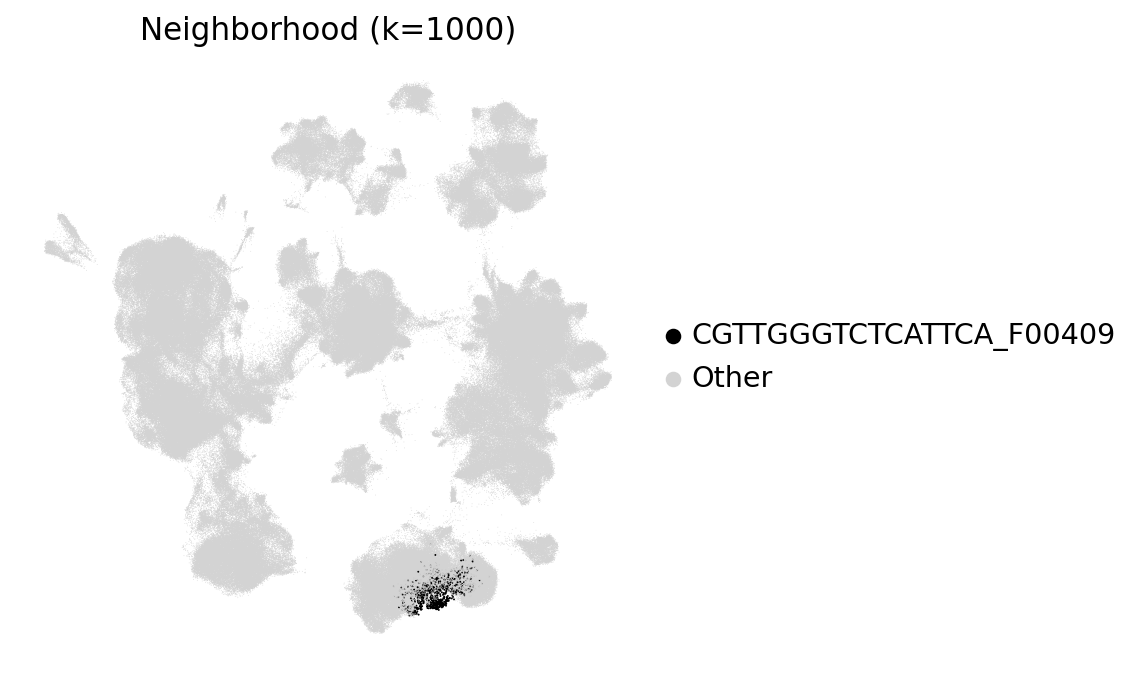

In [42]:
plotting.plot_umap_neighborhood(
    results_healthy, neighborhood=nhood_of_int_healthy_sign, scale=0.5
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


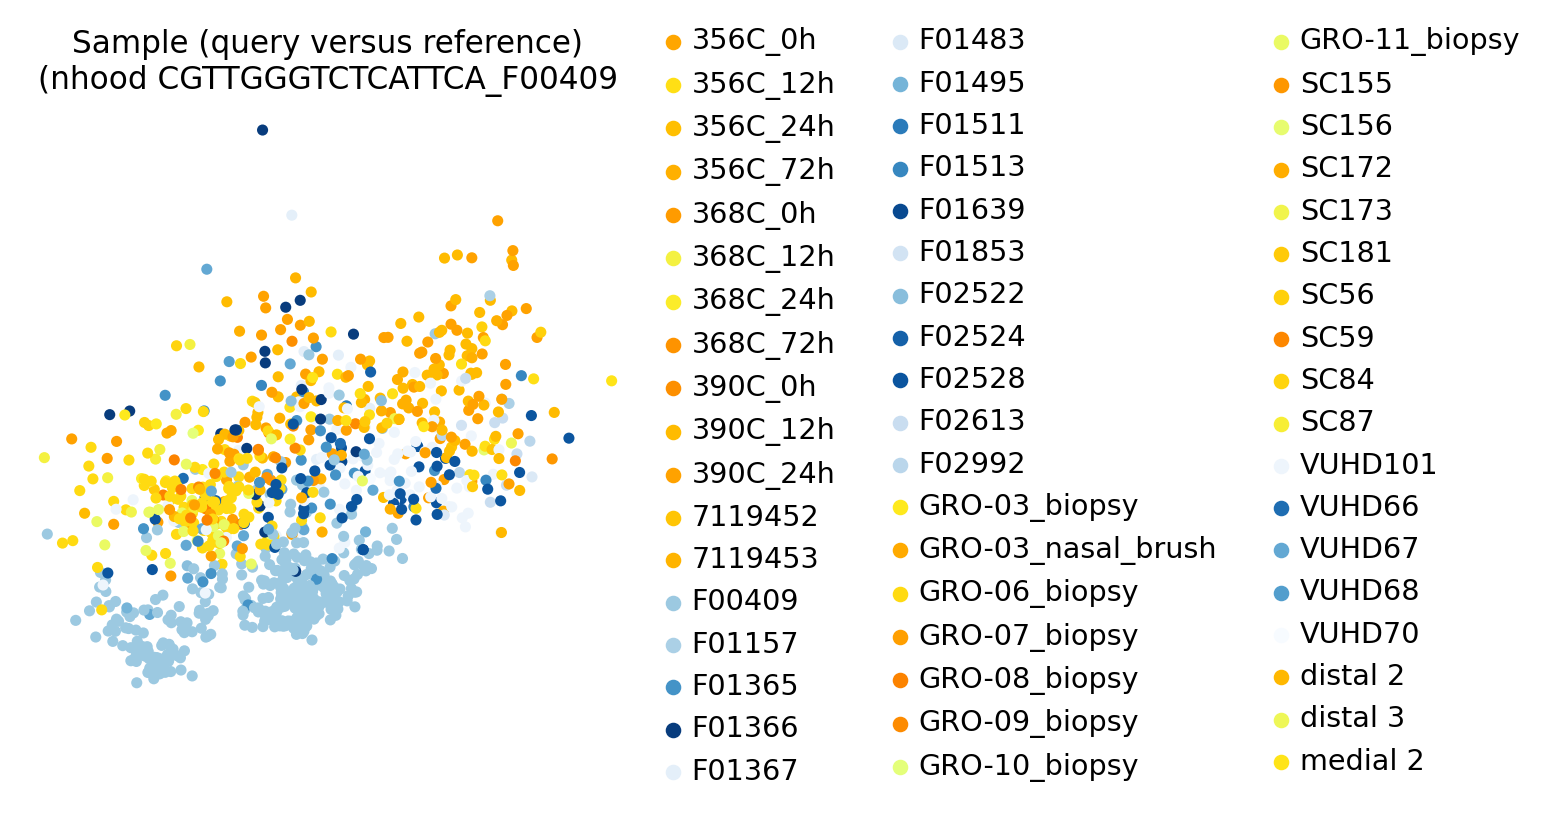

In [43]:
plotting.plot_umap_q_ref_sample_shaded(
    results_healthy,
    neighborhood=nhood_of_int_healthy_sign,
    include_legend=True,
    seed=0,
    dotsize=100,
)

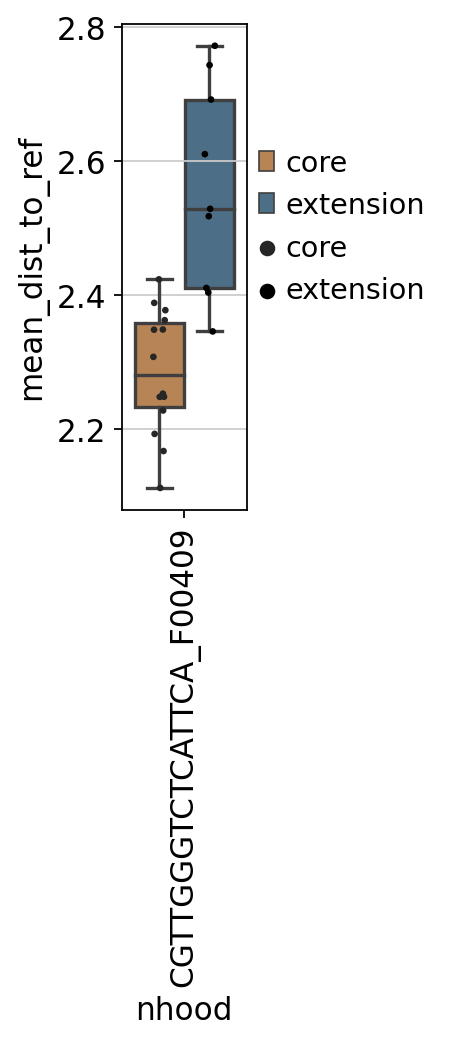

In [44]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(
    results_healthy, neighborhood=nhood_of_int_healthy_sign
)

In [45]:
results_healthy.nhood_stats.loc[nhood_of_int_healthy_sign, :]

ks_stat                              0.81746
pval                                0.000199
nhood_number                              45
nhood_weight                          0.9815
pval_corr                           0.015126
sign                                    True
mean_zscored_q_dist_to_ref          3.039246
cell_type                     T cell lineage
Name: CGTTGGGTCTCATTCA_F00409, dtype: object

In [46]:
# nhood_idx = np.where(mapqc_results.center_cells == neighborhood)[0][0]
# nhood_cells = mapqc_results.nhood_cells[nhood_idx, :]
# adata_to_plot = mapqc_results.adata[nhood_cells, :].copy()

In [47]:
# sc.pl.umap(adata_nhood_healthy)

## Optional: run mapQC on disease

In [48]:
query_cell_idc_disease = np.where(adata_disease.obs[ref_q_key] == query_cat)[0].tolist()
random.seed(0)
center_cell_idc_disease = random.sample(query_cell_idc_disease, k=n_nhoods)
center_cells_disease = np.array(
    adata_disease.obs.iloc[center_cell_idc_disease, :].index
)

In [49]:
results_disease = mapqc.mapQC_results(
    adata=adata_disease,
    center_cells=center_cells_disease,
    k=k,
    emb_key="X",
    ref_q_key="core_or_extension",
    ref_cat="core",
    query_cat="extension",
    batch_key="dataset",
)

../../../atlas_extension/mapqc/mapqc.py:137: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  self._nhood_filtered = pd.Series(index=self.center_cells)


In [50]:
results_disease.calculate_sample_dists_to_ref_samples()

100it [00:24,  4.06it/s]
../../../atlas_extension/mapqc/mapqc.py:242: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)
../../../atlas_extension/mapqc/mapqc.py:246: RuntimeWarning: Mean of empty slice
  nhood_ref_mean_dists = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1872: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [51]:
results_disease.calculate_nhood_statistics()

81% of neighborhoods passed filtering.
47% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.


../../../atlas_extension/mapqc/mapqc.py:311: RuntimeWarning: Mean of empty slice
  mean_zscored_q_dist_to_ref = np.nanmean(


#### Plot disease results:

In [52]:
sc.pl.umap(
    results_disease.adata,
    color="core_or_extension",
    palette={
        results_disease.ref_cat: "tab:orange",
        results_disease.query_cat: "tab:blue",
    },
    title=f"{query_batch} (disease)",
    frameon=False,
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


KeyboardInterrupt: 

In [ ]:
sc.pl.umap(
    results_disease.adata,
    color="ann_level_3",
    # title=f"{query_batch} (disease)",
    frameon=False,
)

In [ ]:
plotting.plot_umap_significance(results_disease)

In [ ]:
plotting.plot_umap_filtering_info(results_disease)

In [ ]:
plotting.plot_umap_q_ref_sample_shaded(results_healthy)

In [ ]:
# plotting.plot_umap_neighborhood(
#     results_disease, neighborhood="...", scale=0.5
# )

In [ ]:
plotting.plot_umap_zscored_q_dist_to_ref(results_disease)

In [ ]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(results_disease)

In [ ]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(
    results_disease, use_zscored_dists=True
)

In [ ]:
plotting.plot_umap_q_ref_sample_shaded(results_disease)

plot specific neighborhood of cell type of interest 1:

In [ ]:
results_disease.nhood_stats["cell_type"] = results_disease.adata.obs.loc[
    results_disease.nhood_stats.index, "ann_level_3"
]

In [ ]:
nhood_of_int_disease = results_disease.nhood_stats.index[
    np.where(results_disease.nhood_stats.cell_type == ctoi_1)[0][0]
]

In [ ]:
plotting.plot_umap_neighborhood(
    results_disease, neighborhood=nhood_of_int_disease, scale=0.5
)

In [ ]:
plotting.plot_umap_q_ref_sample_shaded(
    results_disease, neighborhood=nhood_of_int_disease, include_legend=True
)

In [ ]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(
    results_disease, neighborhood=nhood_of_int_disease
)

pvalue of neighborhood:

In [ ]:
results_disease.nhood_stats.loc[nhood_of_int_disease, :]

In [ ]:
partitioning_key = "ann_level_3"
stats_df_disease = results_disease.nhood_stats.copy()
stats_df_disease[partitioning_key] = results_disease.adata.obs.loc[
    stats_df_disease.index, partitioning_key
]
stats_df_disease["-log10(pval_corr)"] = -np.log10(
    stats_df_disease.pval_corr.values.astype(float)
)
fig = plt.figure(figsize=(9, 3))
ax = fig.add_subplot()
sns.boxplot(
    stats_df_disease, x=partitioning_key, y="-log10(pval_corr)", ax=ax, saturation=0.4
)
sns.stripplot(
    stats_df_disease,
    x=partitioning_key,
    y="-log10(pval_corr)",
    dodge=True,
    ax=ax,
    size=3,
    palette="dark:black",
)
plt.axhline(-np.log10(0.05), linestyle="--")
ax.tick_params(axis="x", rotation=90)
ax.set_xlabel("Cell type")